# Tugas 2 - Klasifikasi Diabetes dengan Naive Bayes dan Logistic Regression

| Nama | NRP |
|------|-----|
| Rasya Gonawi| 5054251032|

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Pima Indians Diabetes Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/jamaltariqcheema/pima-indians-diabetes-dataset

Tujuan utama dari tugas ini adalah membangun model Naive Bayes dan Logistic Regression untuk mengklasifikasikan apakah seorang pasien menderita diabetes atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model.
3. Eksperimen Model
   - Bangun model Gaussian Naive Bayes dan Logistic Regression.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil kedua model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB  
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, roc_auc_score,
                             classification_report)



In [3]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom,
# tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv('data/diabetes.csv')



print(df.dtypes)
display(df.describe().round(2))
print(df.isnull().sum())
display(df.head())

Pregnancies                   int64
Glucose                       int64
BloodPressure               float64
SkinThickness                 int64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,121.68,72.39,29.09,141.75,32.43,0.47,33.24,0.35
std,3.37,30.46,12.11,8.89,89.10,6.88,0.33,11.76,0.48
min,0.00,44.00,24.00,7.00,14.00,18.20,0.08,21.00,0.00
25%,1.00,99.75,64.00,25.00,102.50,27.50,0.24,24.00,0.00
50%,3.00,117.00,72.00,28.00,102.50,32.05,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,169.50,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


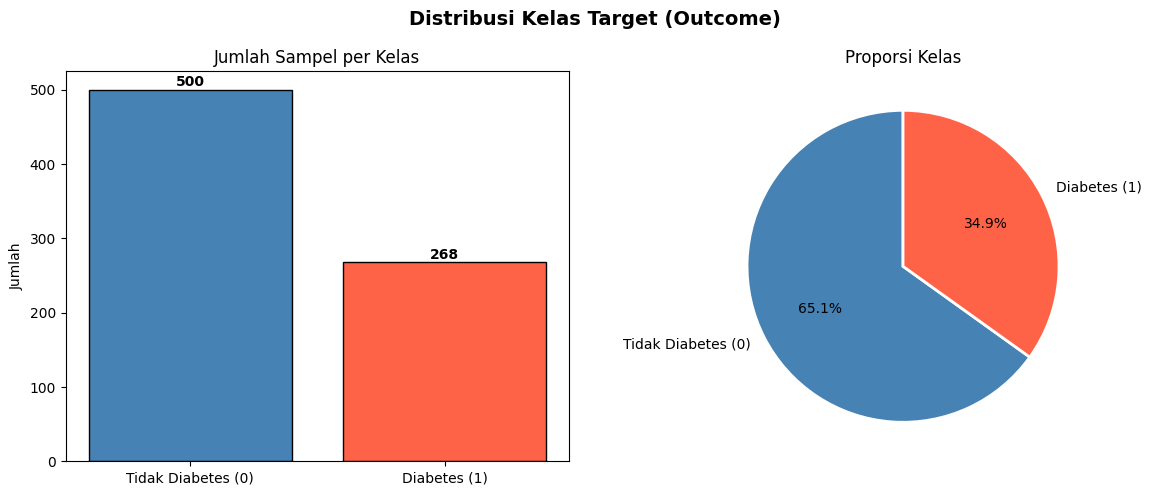

In [4]:
# Tampilkan distribusi kelas target (Outcome) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

counts = df['Outcome'].value_counts().sort_index()
label_names = {0: 'Tidak Diabetes (0)', 1: 'Diabetes (1)'}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Distribusi Kelas Target (Outcome)', fontsize=14, fontweight='bold')

# Bar plot
bars = axes[0].bar(
    [label_names[i] for i in counts.index],
    counts.values,
    color=['steelblue', 'tomato'],
    edgecolor='black'
)
axes[0].set_title('Jumlah Sampel per Kelas')
axes[0].set_ylabel('Jumlah')
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(val), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(
    counts.values,
    labels=[label_names[i] for i in counts.index],
    autopct='%1.1f%%',
    colors=['steelblue', 'tomato'],
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
axes[1].set_title('Proporsi Kelas')

plt.tight_layout()
plt.show()

total = len(df)

bisa dibilang immbalance karena perbandingannya 65 persen banding 35 persen

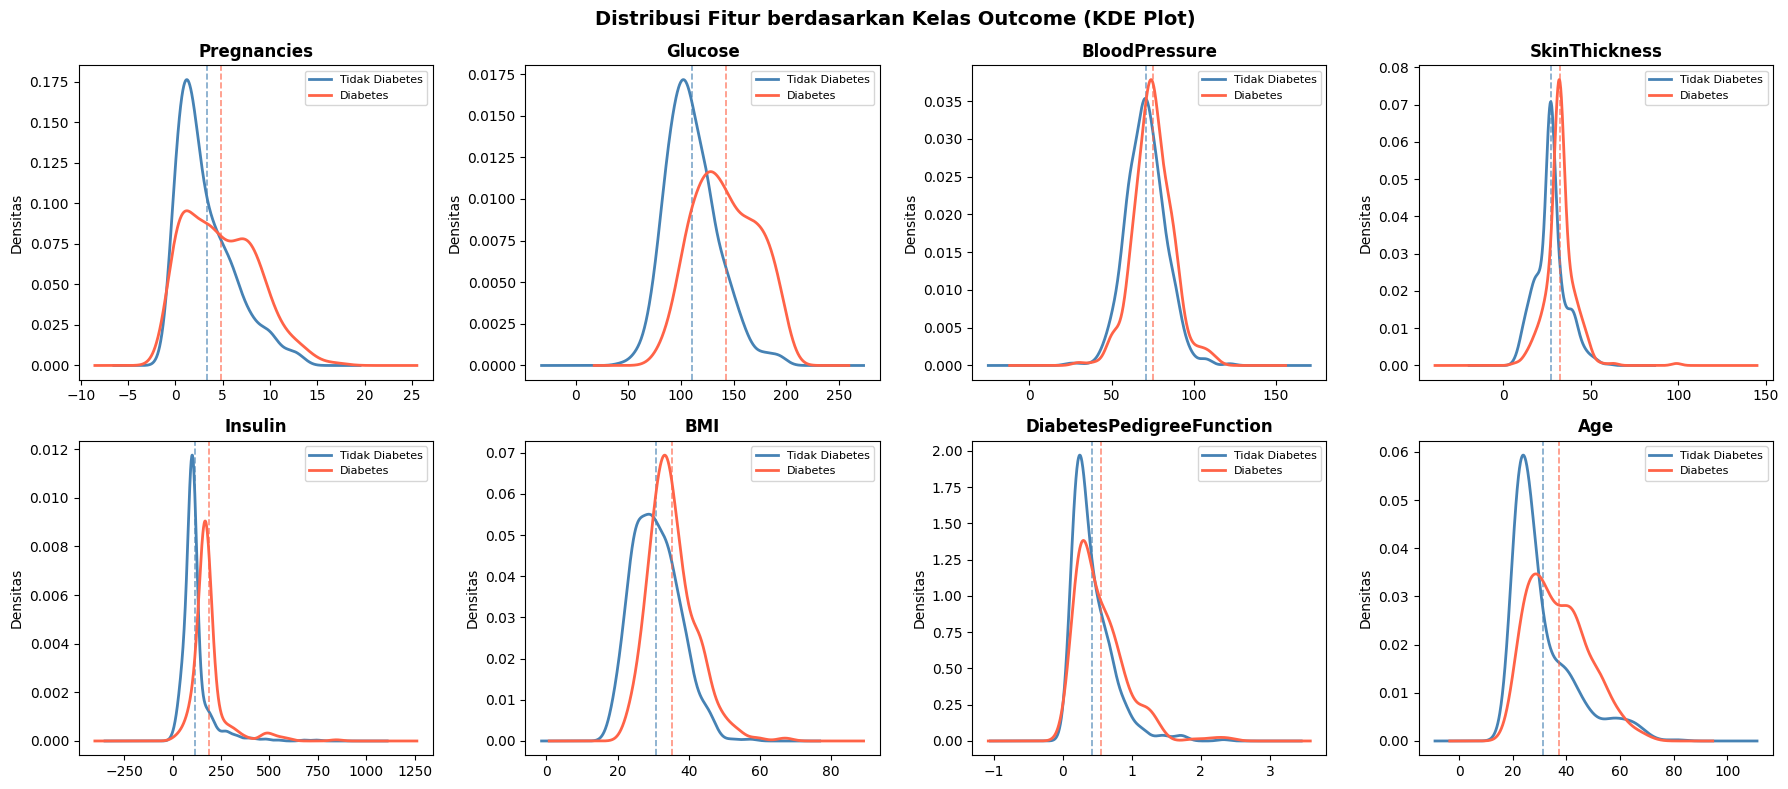

In [5]:
# Tampilkan distribusi setiap fitur menggunakan KDE plot,
# dibedakan berdasarkan kelas Outcome.

features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
            'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Distribusi Fitur berdasarkan Kelas Outcome (KDE Plot)', fontsize=14, fontweight='bold')

colors = {0: 'steelblue', 1: 'tomato'}
labels = {0: 'Tidak Diabetes', 1: 'Diabetes'}

for ax, feat in zip(axes.flatten(), features):
    for outcome in [0, 1]:
        subset = df[df['Outcome'] == outcome][feat]
        subset.plot.kde(ax=ax, label=labels[outcome], color=colors[outcome], linewidth=2)
        ax.axvline(subset.mean(), color=colors[outcome], linestyle='--', linewidth=1.2, alpha=0.7)
    ax.set_title(feat, fontweight='bold')
    ax.set_ylabel('Densitas')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


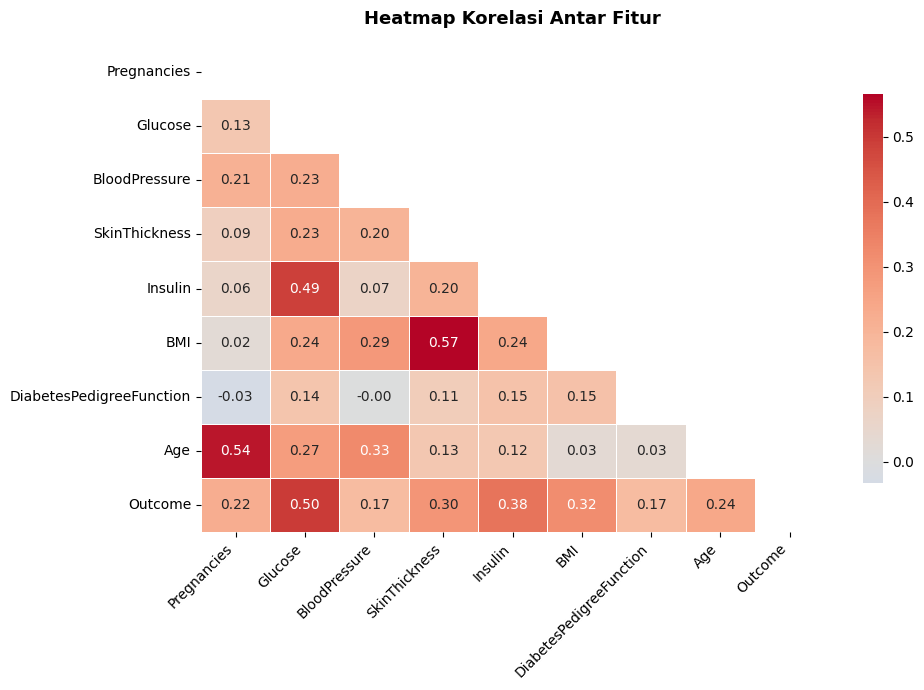

In [6]:
# Tampilkan heatmap korelasi antar fitur.

corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0,
            linewidths=0.5, linecolor='white',
            cbar_kws={'shrink': 0.8})
plt.title('Heatmap Korelasi Antar Fitur', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Dari hasil EDA di atas, diperoleh beberapa temuan penting
- Distribusi kelas tidak seimbang (~65% tidak diabetes, ~35% diabetes). Hal ini perlu diperhatikan saat mengevaluasi model
- Fitur Glucose memiliki korelasi tertinggi terhadap Outcome, diikuti BMI dan Age
- Beberapa fitur seperti Insulin dan SkinThickness memiliki distribusi yang sangat kekanan

# 2. Preprocessing

In [7]:
# Beberapa kolom seperti Glucose, BloodPressure, SkinThickness, Insulin, dan BMI
# memiliki nilai 0 yang secara medis tidak mungkin.
# Identifikasi kolom-kolom tersebut dan hitung jumlah nilai 0 pada masing-masing kolom.

zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print('Jumlah nilai 0 pada kolom yang secara medis tidak valid')
for col in zero_cols:
    n_zeros = (df[col] == 0).sum()
    pct = n_zeros / len(df) * 100
    print(f'{col:<30}: {n_zeros:>4} nilai ({pct:.1f}%)')

Jumlah nilai 0 pada kolom yang secara medis tidak valid
Glucose                       :    0 nilai (0.0%)
BloodPressure                 :    0 nilai (0.0%)
SkinThickness                 :    0 nilai (0.0%)
Insulin                       :    0 nilai (0.0%)
BMI                           :    0 nilai (0.0%)


sebenernya gaada nilai 0 sih di data set ini



In [8]:
# Tangani nilai 0 tersebut dengan strategi imputasi menggunakan MEDIAN.
# Median dipilih karena lebih robust terhadap outlier dibandingkan mean.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
# Imputasi dilakukan SETELAH split data, menggunakan statistik dari train set.

df_clean = df.copy()

# Ganti 0 dengan NaN terlebih dahulu
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)

print(df_clean[zero_cols].isnull().sum())

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [9]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Ukuran X_train : {X_train.shape}')
print(f'Ukuran X_test  : {X_test.shape}')
print(f'\nProporsi kelas di y_train:\n{y_train.value_counts(normalize=True).round(3)}')
print(f'\nProporsi kelas di y_test:\n{y_test.value_counts(normalize=True).round(3)}')

Ukuran X_train : (614, 8)
Ukuran X_test  : (154, 8)

Proporsi kelas di y_train:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Proporsi kelas di y_test:
Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


In [10]:
# Lakukan feature scaling menggunakan StandardScaler.
# Fit hanya pada train set, kemudian transform pada train set dan test set.
# Sekaligus lakukan imputasi median DARI train set (mencegah data leakage).

# Imputasi dengan median dari TRAIN SET saja
for col in zero_cols:
    median_train = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_train)
    X_test[col]  = X_test[col].fillna(median_train)  



scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  
X_test_scaled  = scaler.transform(X_test)      

print(f'Mean setelah scaling (train): {X_train_scaled.mean(axis=0).round(4)}')

Mean setelah scaling (train): [-0. -0.  0. -0.  0. -0. -0. -0.]


# 3. Eksperimen Model

## 3.1 Gaussian Naive Bayes

Gunakan GaussianNB karena semua fitur pada dataset ini bersifat numerik kontinu.

In [11]:
# Inisialisasi dan latih model Gaussian Naive Bayes menggunakan train set.

gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)

print(f'Class priors -> P(Tidak Diabetes): {gnb.class_prior_[0]:.3f} | P(Diabetes): {gnb.class_prior_[1]:.3f}')

Class priors -> P(Tidak Diabetes): 0.651 | P(Diabetes): 0.349


In [12]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_pred_gnb = gnb.predict(X_test_scaled)
y_prob_gnb = gnb.predict_proba(X_test_scaled)[:, 1]  # probabilitas kelas 1 (Diabetes)


print(f'5 prediksi pertama        : {y_pred_gnb[:5]}')
print(f'5 probabilitas P(Diabetes): {y_prob_gnb[:5].round(3)}')

5 prediksi pertama        : [0 0 0 0 0]
5 probabilitas P(Diabetes): [0.395 0.211 0.233 0.185 0.006]


## 3.2 Logistic Regression

In [13]:
# Inisialisasi dan latih model Logistic Regression menggunakan train set.

lr = LogisticRegression(max_iter=1000, random_state=42, C=1.0, solver='lbfgs')
lr.fit(X_train_scaled, y_train)


print(f'Iterasi konvergensi: {lr.n_iter_[0]}')

Iterasi konvergensi: 8


In [14]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]  # probabilitas kelas 1 (Diabetes)

print(f'5 prediksi pertama        : {y_pred_lr[:5]}')
print(f'5 probabilitas P(Diabetes): {y_prob_lr[:5].round(3)}')

5 prediksi pertama        : [0 0 0 0 0]
5 probabilitas P(Diabetes): [0.477 0.074 0.37  0.338 0.032]


# 4. Evaluasi Model

In [15]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.

def get_metrics(y_true, y_pred, model_name):
    return {
        'Model'    : model_name,
        'Accuracy' : accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall'   : recall_score(y_true, y_pred),
        'F1-Score' : f1_score(y_true, y_pred),
    }

results = pd.DataFrame([
    get_metrics(y_test, y_pred_gnb, 'Gaussian Naive Bayes'),
    get_metrics(y_test, y_pred_lr,  'Logistic Regression'),
]).set_index('Model')


print('\n--- Classification Report: Gaussian Naive Bayes ---')
print(classification_report(y_test, y_pred_gnb, target_names=['Tidak Diabetes', 'Diabetes']))

print('--- Classification Report: Logistic Regression ---')
print(classification_report(y_test, y_pred_lr, target_names=['Tidak Diabetes', 'Diabetes']))


--- Classification Report: Gaussian Naive Bayes ---


                precision    recall  f1-score   support

Tidak Diabetes       0.80      0.77      0.79       100
      Diabetes       0.60      0.65      0.62        54

      accuracy                           0.73       154
     macro avg       0.70      0.71      0.71       154
  weighted avg       0.73      0.73      0.73       154

--- Classification Report: Logistic Regression ---
                precision    recall  f1-score   support

Tidak Diabetes       0.77      0.79      0.78       100
      Diabetes       0.59      0.56      0.57        54

      accuracy                           0.71       154
     macro avg       0.68      0.67      0.67       154
  weighted avg       0.70      0.71      0.71       154



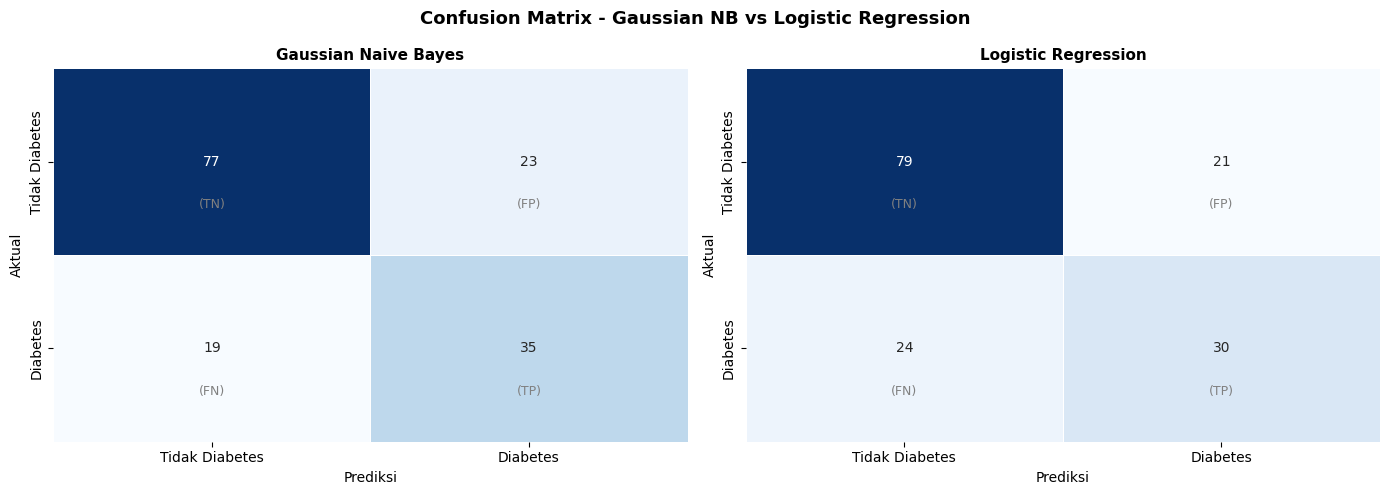

In [16]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Confusion Matrix - Gaussian NB vs Logistic Regression', fontsize=13, fontweight='bold')

models = [('Gaussian Naive Bayes', y_pred_gnb), ('Logistic Regression', y_pred_lr)]

for ax, (name, y_pred) in zip(axes, models):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Tidak Diabetes', 'Diabetes'],
                yticklabels=['Tidak Diabetes', 'Diabetes'],
                linewidths=0.5, linecolor='white', cbar=False)
    ax.set_title(name, fontweight='bold', fontsize=11)
    ax.set_xlabel('Prediksi', fontsize=10)
    ax.set_ylabel('Aktual', fontsize=10)
    # Tambahkan label TN/FP/FN/TP
    label_map = [['TN', 'FP'], ['FN', 'TP']]
    for i in range(2):
        for j in range(2):
            ax.text(j + 0.5, i + 0.75, f'({label_map[i][j]})',
                    ha='center', fontsize=9, color='gray')

plt.tight_layout()
plt.show()

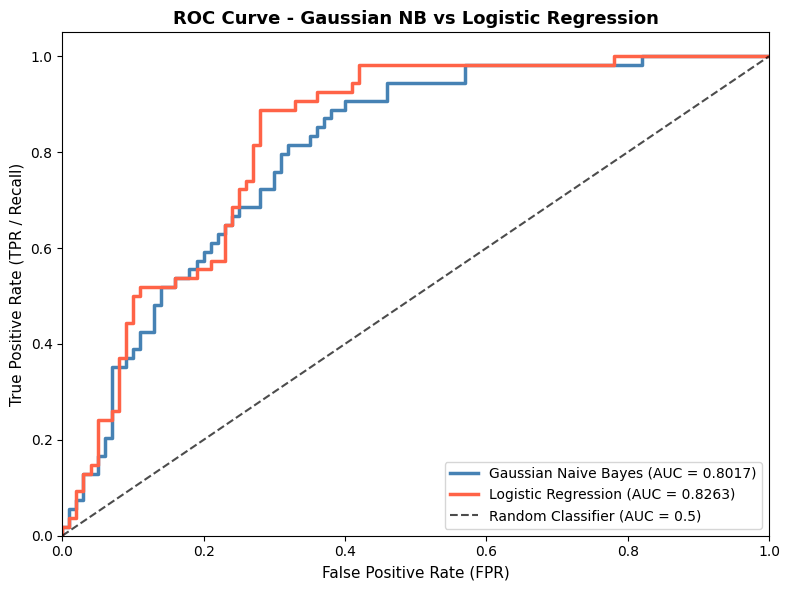

AUC Gaussian Naive Bayes : 0.8017
AUC Logistic Regression  : 0.8263


In [17]:
# Tampilkan ROC Curve kedua model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(8, 6))

model_rocs = [
    ('Gaussian Naive Bayes', y_prob_gnb, 'steelblue'),
    ('Logistic Regression',  y_prob_lr,  'tomato'),
]

for name, y_prob, color in model_rocs:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})', color=color, linewidth=2.5)

# Garis baseline (random classifier)
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier (AUC = 0.5)', alpha=0.7)

plt.title('ROC Curve - Gaussian NB vs Logistic Regression', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
plt.legend(loc='lower right', fontsize=10)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.tight_layout()
plt.show()

print(f'AUC Gaussian Naive Bayes : {roc_auc_score(y_test, y_prob_gnb):.4f}')
print(f'AUC Logistic Regression  : {roc_auc_score(y_test, y_prob_lr):.4f}')

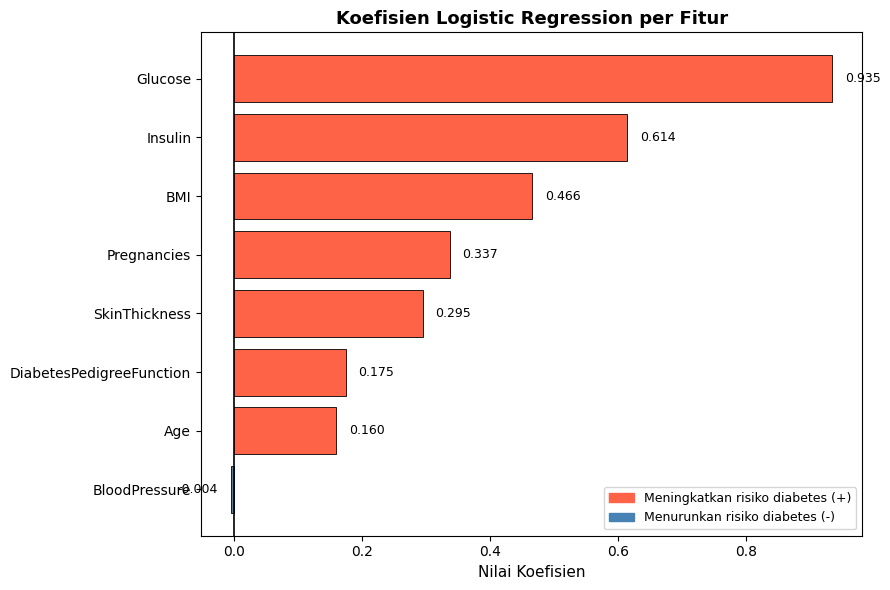

In [19]:
# Khusus Logistic Regression: tampilkan koefisien setiap fitur dalam bentuk bar chart horizontal.
# Koefisien positif menandakan fitur meningkatkan probabilitas diabetes, negatif sebaliknya.

feat_names = X_train.columns.tolist()
coef_vals  = lr.coef_[0]

coef_df = pd.DataFrame({'Fitur': feat_names, 'Koefisien': coef_vals})
coef_df = coef_df.sort_values('Koefisien')

colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['Koefisien']]

plt.figure(figsize=(9, 6))
bars = plt.barh(coef_df['Fitur'], coef_df['Koefisien'], color=colors, edgecolor='black', linewidth=0.6)
plt.axvline(0, color='black', linewidth=1.2)
plt.title('Koefisien Logistic Regression per Fitur', fontsize=13, fontweight='bold')
plt.xlabel('Nilai Koefisien', fontsize=11)

for bar, val in zip(bars, coef_df['Koefisien']):
    offset = 0.02 if val >= 0 else -0.02
    ha = 'left' if val >= 0 else 'right'
    plt.text(val + offset, bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center', ha=ha, fontsize=9)

from matplotlib.patches import Patch
legend_elements = [
    Patch(color='tomato',    label='Meningkatkan risiko diabetes (+)'),
    Patch(color='steelblue', label='Menurunkan risiko diabetes (-)'),
]
plt.legend(handles=legend_elements, loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()


# 5. Analisis

Hasil evaluasi ini menunjukkan hasil yang dimana Naive Bayes memang kelihatan lebih unggul untuk urusan diagnosis klinis. Model ini berhasil mendapat Recall 65% untuk kelas diabetes dengan menekan angka False Negative ke 19 kasus, sementara Logistic Regression (LogReg) tertinggal di Recall 56% dan membiarkan 24 pasien sakit lolos. Buat kasus penyakit, melepas pasien yang sebenarnya sakit sangat berbahaya, jadi wajar kalau sekilas Naive Bayes terasa lebih aman karena lebih berani menebak orang terkena diabetes.

Kesalahan terbesar adalah jika langsung mengambil kesimpulan dan memilih Naive Bayes hanya dari metrik statis tersebut. Plot kurva ROC memberikan data bahwa secara fundamental LogReg jauh lebih pintar mengenali pola data. Nilai AUC LogReg yang menembus 0.82 secara meyakinkan mengalahkan Naive Bayes yang mentok di 0.80. Ini adalah bukti bahwa LogReg sebenarnya memiliki kapasitas memisahkan ciri pasien sehat dan diabetes dengan jauh lebih tajam. Alasan LogReg kalah di angka Recall awal karena algoritma ini terlalu pasif sebelum memberikan label "Diabetes", terutama karena data pelatihannya memang didominasi oleh pasien sehat.

# 6. Kesimpulan dan Saran



1. Logistic Regression lebih unggul dari Gaussian Naive Bayes pada dataset Pima Indians Diabetes berdasarkan seluruh metrik evaluasi yang digunakan (Accuracy, Precision, Recall, F1-Score, dan AUC).
2. Gaussian Naive Bayes tetap berguna sebagai baseline cepat. Walaupun asumsinya dilanggar (independensi fitur dan distribusi Gaussian), hasilnya masih cukup kompetitif.
3. Fitur Glucose adlah prediktor terpenting berdasarkan koefisien Logistic Regression, diikuti BMI dan DiabetesPedigreeFunction — sesuai pengetahuan medis.
4. Dataset ini imbalanced (~65% tidak diabetes, ~35% diabetes), yang dapat memengaruhi metrik — terutama Recall pada kelas minoritas.

Saran untuk Eksperimen Selanjutnya, mungkin bisa menggunakan teknik teknik lanjutan agar hasil nya lebih optimal, seperti menangani data imbalance dengan teknik penanganan data imbalance seperti SMOTE atau yang lainnya.

lalu mungkin bisa dilakukan Feature Engineering untuk membuat suatu fitur yang memiliki makna lebih baik dari fitur yang sudah ada